# 01. Resonator and SQUID parameters from VNA flux sweeps

A simulation is only as good as the device it is given. This notebook extracts every fitted parameter of the virtual
channel from VNA measurements, as in Sec. IV B of the paper (Table I and Fig. 3): circle fits of $S_{21}$ at every flux
bias give the resonator ($Q_r$, $|\hat Q_c|$, $\alpha$), and a fit of the resonance frequency against the flux-ramp
current gives the rf-SQUID ($f_0$, $\lambda$, $M_c$, $M_\mathrm{fr}$ and the trapped flux); $L_s$, $L_c$, $C_c$, $Z_0$
and $M_\mathrm{in}$ are fixed. It then writes the two configuration files into `results/configs/` and checks them
against the copies shipped in `configs/`, which are the ones the later notebooks load. Data:
`data/vna/res2_flux_power_sweep_2026-09-26.npz` (16 powers $\times$ 101 flux biases $\times$ 1001 frequencies) and
`data/vna/res2_flux_sweep_2026-10-04.npz` (one power). Run time a little over a minute, almost all of it in the 1717
circle fits and the 19 flux-response fits.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time
from umux_cmt import fitting
from umux_cmt.fitting import plots

SWEEPS = {"09/26": DATA / "vna" / "res2_flux_power_sweep_2026-09-26.npz",
          "10/04": DATA / "vna" / "res2_flux_sweep_2026-10-04.npz"}
M_NOMINAL = 14.4e-12     # H, design mutual of the flux-ramp coil; the flux axes of the sweeps are in Phi0 at this value
LS = 24.2e-12            # H, SQUID loop inductance, fixed: the value the paper assumes (design 22.4 pH)
P_EXTRACT = -26          # dBm at the VNA output, the extraction power (the 10/04 sweep has only -25 dBm)
EDGE_BAND = 1.2e6        # Hz, band at each edge of a sweep used for the cable delay
ATTEN = store.value("Atten", default=-62.9)     # dB from the VNA output to the chip, fitted in notebook 05

## 1. The two sweeps

Each sweep holds the complex $S_{21}$ around resonator 2 at 101 flux biases. The flux axis is nominal: it was
programmed in $\Phi_0$ assuming the design mutual inductance of the flux-ramp coil, $M_\mathrm{fr} = 14.4$ pH, so what
was actually applied is the coil current $I = \Phi_\mathrm{nominal}\,\Phi_0 / 14.4\,\mathrm{pH}$, and the true mutual is
one of the fitted parameters. Powers are VNA output powers. The power at the chip is $P_\mathrm{VNA} + A$, with the line
attenuation $A \approx -62.9$ dB that notebook 05 fits from the power dependence of the 09/26 sweep; it is read from
`results/values.json`, with the paper's value as the default.

In [2]:
sweeps = {day: uc.load_vna_sweep(path) for day, path in SWEEPS.items()}
I = {day: sw.bias_current(M_NOMINAL) for day, sw in sweeps.items()}
k_ext = {day: sw.power_index(P_EXTRACT) for day, sw in sweeps.items()}

print(f"attenuation from the VNA output to the chip: A = {ATTEN:.2f} dB\n")
for day, sw in sweeps.items():
    n_power, n_flux, n_f = sw.shape
    P = sw.powers
    print(f"{day}: {n_power} power(s) x {n_flux} flux biases x {n_f} frequencies, "
          f"{sw.f[0] / 1e6:.1f}-{sw.f[-1] / 1e6:.1f} MHz in {(sw.f[1] - sw.f[0]) / 1e3:.1f} kHz steps")
    print(f"       flux bias {sw.flux[0]:.2f}-{sw.flux[-1]:.2f} Phi0 (nominal) = coil current "
          f"{I[day][0] * 1e3:.3f}-{I[day][-1] * 1e3:.3f} mA")
    powers = f"{P[0]:.0f} to {P[-1]:.0f} dBm in {P[1] - P[0]:.0f} dB steps" if n_power > 1 else f"{P[0]:.0f} dBm"
    print(f"       VNA power {powers}; extraction at {P[k_ext[day]]:.0f} dBm = {P[k_ext[day]] + ATTEN:.1f} dBm at the chip")

attenuation from the VNA output to the chip: A = -62.90 dB

09/26: 16 power(s) x 101 flux biases x 1001 frequencies, 5511.6-5520.0 MHz in 8.4 kHz steps
       flux bias 0.00-2.00 Phi0 (nominal) = coil current 0.000-0.287 mA
       VNA power -40 to -10 dBm in 2 dB steps; extraction at -26 dBm = -88.9 dBm at the chip
10/04: 1 power(s) x 101 flux biases x 1001 frequencies, 5513.0-5516.8 MHz in 3.8 kHz steps
       flux bias 0.00-1.50 Phi0 (nominal) = coil current 0.000-0.215 mA
       VNA power -25 dBm; extraction at -25 dBm = -87.9 dBm at the chip


## 2. One trace: the cable delay and the notch fit

We start with a single trace, at the extraction power ($-26$ dBm at the VNA, $-89$ dBm at the chip) and zero flux bias.
Off resonance $|S_{21}|$ is flat, but the phase falls linearly with frequency: the probe takes a time $\tau$ to travel
through the cables, which multiplies $S_{21}$ by $e^{-2\pi i f \tau}$, and the delay has to be removed before the
resonance traces a circle in the complex plane. `fit_resonance_trace` fits a straight line to the unwrapped phase in a
1.2 MHz band at each edge of the sweep (shaded), on this first pass without the points within 1.5 MHz of the dip (none
here; on the narrow 10/04 sweep less than half of the bands remain, mostly on one side of the dip). It removes the line
and fits the notch, then divides the fitted notch out of the raw trace, fits the line to the full bands again, and
iterates until $\tau$ changes by less than 5 ps. Dividing the notch out removes the resonance's own phase tail from the
edge bands, so we call this the tail-corrected delay; that is also why the dashed line, the final delay, runs above the
measured phase in the left band and below it in the right one.

TraceFit(fr=5515.9585 MHz, Qr=9595, Qc_abs=10505, alpha=-0.0875, tau=87.03 ns, n_iter=4, converged=True)


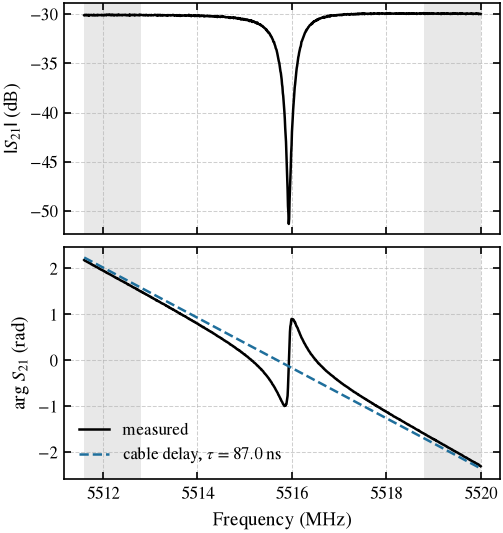

In [3]:
sw = sweeps["09/26"]
f, s21 = sw.f, sw.s21[k_ext["09/26"], 0]
trace = fitting.fit_resonance_trace(f, s21, edge_band=EDGE_BAND)
print(trace)

phase = np.unwrap(np.angle(s21))
delay_line = np.unwrap(np.angle(s21 / trace.s21_corrected))       # the fitted line, -2 pi f tau + const
delay_line += 2 * np.pi * np.round((phase - delay_line)[0] / (2 * np.pi))

fig, (ax_db, ax_ph) = plt.subplots(2, 1, figsize=(SINGLE, 3.6), sharex=True)
ax_db.plot(f / 1e6, 20 * np.log10(np.abs(s21)), color=MEASURED)
ax_ph.plot(f / 1e6, phase, color=MEASURED, label="measured")
ax_ph.plot(f / 1e6, delay_line, color=BLUE, ls="--", label=rf"cable delay, $\tau$ = {trace.tau * 1e9:.1f} ns")
for ax in (ax_db, ax_ph):
    ax.axvspan(f[0] / 1e6, (f[0] + EDGE_BAND) / 1e6, color=GRAY, alpha=0.15, lw=0)
    ax.axvspan((f[-1] - EDGE_BAND) / 1e6, f[-1] / 1e6, color=GRAY, alpha=0.15, lw=0)
    grid(ax)
ax_db.set_ylabel(r"$|S_{21}|$ (dB)")
ax_ph.set_ylabel(r"arg $S_{21}$ (rad)")
ax_ph.set_xlabel("Frequency (MHz)")
ax_ph.legend(loc="lower left")
save(fig, "01_raw_trace", RESULTS / "figures")
plt.show()

With the delay removed, the notch model (Khalil et al. 2012, Probst et al. 2015)
$$S_{21}(f) = a\,e^{i\phi_\mathrm{bg}}\left[1 - \frac{e^{i\alpha}\,Q_r/|\hat Q_c|}{1 + 2iQ_r(f - f_r)/f_r}\right]$$
is fitted to the points within 1.5 MHz of the dip in three stages: an algebraic circle fit, an arctangent fit of the
phase around the circle's centre for $f_r$ and $Q_r$, and a weighted least-squares fit of the full complex model. The
asymmetry angle $\alpha$ tilts the circle (impedance mismatches around the resonator); the coupling quality factor the
simulation needs is the real part, $Q_c = |\hat Q_c|/\cos\alpha$ (the diameter correction method), and
$1/Q_i = 1/Q_r - 1/Q_c$. The diagnostic plot of `fitting.plots` shows the delay-corrected data in the fit window (black)
and the fitted notch (blue).

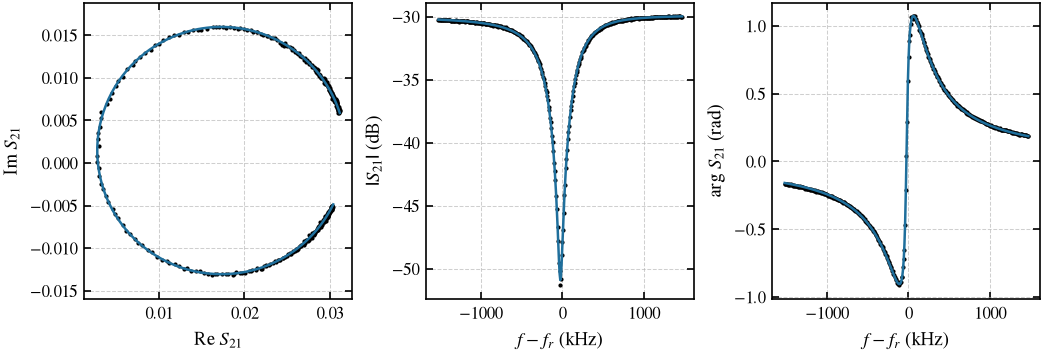

fr = 5515.9585 MHz, Qr = 9595, |Qc| = 10505, alpha = -0.0875 rad
Qc = |Qc|/cos(alpha) = 10545, Qi = 106496, linewidth fr/Qr = 575 kHz


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.4))
plots.notch_panels(f, trace, axes=axes, data_kw=dict(color=MEASURED, ms=2), fit_kw=dict(color=BLUE))
axes[1].set_title("")
for ax in axes:
    grid(ax)
save(fig, "01_notch_fit", RESULTS / "figures")
plt.show()

print(f"fr = {trace.fr / 1e6:.4f} MHz, Qr = {trace.Qr:.0f}, |Qc| = {trace.Qc_abs:.0f}, alpha = {trace.alpha:.4f} rad")
print(f"Qc = |Qc|/cos(alpha) = {trace.Qc_dcm:.0f}, Qi = {trace.Qi:.0f}, linewidth fr/Qr = {trace.linewidth / 1e3:.0f} kHz")

Why not fit the line to the raw edge phase and be done? Because the resonance's phase tail reaches into the edge
bands: the line absorbs part of the resonance, the delay comes out short, and the circle that is left is distorted so
that $Q_r$ and $|\hat Q_c|$ come out a few percent high. The check below makes a synthetic twin of this trace, the
fitted notch with the fitted delay and no noise, whose parameters are therefore known, and fits it both ways: one pass
on the raw edge phase (`max_iter=1`) and the iterated, tail-corrected delay. The measured trace is then fitted on its
raw edge phase too. The columns dQr and d|Qc| are relative to the first row: the tail-corrected fit of the measured
trace, whose values are the twin's true parameters.

In [5]:
twin = trace.model(f) * np.exp(-2j * np.pi * trace.tau * f)

print(f"{'':34}{'delay (ns)':>11}{'Qr':>9}{'|Qc|':>9}{'alpha':>9}{'dQr':>9}{'d|Qc|':>9}")
print(f"{'measured, tail-corrected = twin':34}{trace.tau * 1e9:11.2f}{trace.Qr:9.1f}{trace.Qc_abs:9.1f}{trace.alpha:9.4f}")
for name, s, how in (("synthetic twin, raw edge phase", twin, dict(max_iter=1)),
                     ("synthetic twin, tail-corrected", twin, {}),
                     ("measured, raw edge phase", s21, dict(max_iter=1))):
    t = fitting.fit_resonance_trace(f, s, edge_band=EDGE_BAND, **how)
    print(f"{name:34}{t.tau * 1e9:11.2f}{t.Qr:9.1f}{t.Qc_abs:9.1f}{t.alpha:9.4f}"
          f"{t.Qr / trace.Qr - 1:+9.2%}{t.Qc_abs / trace.Qc_abs - 1:+9.2%}")

                                   delay (ns)       Qr     |Qc|    alpha      dQr    d|Qc|
measured, tail-corrected = twin         87.03   9595.3  10505.1  -0.0875
synthetic twin, raw edge phase          83.85   9818.9  10756.2  -0.0896   +2.33%   +2.39%
synthetic twin, tail-corrected          87.03   9595.3  10505.1  -0.0875   +0.00%   +0.00%
measured, raw edge phase                83.85   9824.5  10762.2  -0.0896   +2.39%   +2.45%


## 3. Every trace

The same fit runs on all 1616 traces of the 09/26 sweep and the 101 of 10/04 (about 30 s). $Q_r$, $|\hat Q_c|$ and
$\alpha$ should not depend on flux, since the SQUID shifts the resonance without adding loss, so their scatter over the
101 flux points shows how well each trace pins them down, and their medians at the extraction power go into Table I.
With power, $Q_r$ and $|\hat Q_c|$ stay within about 3%, while $\alpha$ drifts and scatters at the highest powers, where
the RF dressing of the SQUID bends the line shape away from a Lorentzian notch. The two lines after the table repeat the
raw-edge comparison on every trace at the extraction power: the 2.5% bias on 09/26, and a larger one of the other sign on
the narrow 10/04 sweep. There the first pass fits the line to what the dip exclusion leaves of the edge bands, 1.5 to
2.6 MHz from the dip and mostly on one side of it, where the resonance's phase tail tilts it.

In [6]:
t0 = time.perf_counter()
fits = {day: [[fitting.fit_resonance_trace(sw.f, s, edge_band=EDGE_BAND) for s in row] for row in sw.s21]
        for day, sw in sweeps.items()}
par = {day: {name: np.array([[getattr(t, name) for t in row] for row in rows])
             for name in ("fr", "Qr", "Qc_abs", "alpha", "tau")}
       for day, rows in fits.items()}
n_fits = sum(p["fr"].size for p in par.values())
n_failed = sum(np.isnan(p["fr"]).sum() for p in par.values())
print(f"{n_fits} circle fits in {time.perf_counter() - t0:.0f} s, {n_failed} failed\n")


def med_sd(x, decimals):
    return f"{np.median(x):.{decimals}f} ({np.std(x):.{decimals}f})"


print(f"{'':7}{'P_VNA':>6}{'P_chip':>8}{'Qr':>14}{'|Qc|':>14}{'alpha (rad)':>19}   median (sd) over the flux points")
for day, sw in sweeps.items():
    p = par[day]
    for k, P in enumerate(sw.powers):
        print(f"{day:7}{P:6.0f}{P + ATTEN:8.1f}{med_sd(p['Qr'][k], 0):>14}{med_sd(p['Qc_abs'][k], 0):>14}"
              f"{med_sd(p['alpha'][k], 4):>19}")

print("\nextraction power, delay from the raw edge phase instead (first pass only), against the tail-corrected fits:")
for day, sw in sweeps.items():
    k, p = k_ext[day], par[day]
    raw = [fitting.fit_resonance_trace(sw.f, s, edge_band=EDGE_BAND, max_iter=1) for s in sw.s21[k]]
    rel = {name: np.median([getattr(t, name) for t in raw]) / np.median(p[name][k]) - 1 for name in ("Qr", "Qc_abs")}
    d_tau = np.median([t.tau for t in raw]) - np.median(p["tau"][k])
    print(f"  {day}: delay {d_tau * 1e9:+.1f} ns, median Qr {100 * rel['Qr']:+.1f}%, median |Qc| {100 * rel['Qc_abs']:+.1f}%")

1717 circle fits in 27 s, 0 failed

        P_VNA  P_chip            Qr          |Qc|        alpha (rad)   median (sd) over the flux points
09/26     -40  -102.9    9433 (138)    10464 (90)   -0.0896 (0.0040)
09/26     -38  -100.9    9433 (139)    10466 (92)   -0.0895 (0.0034)
09/26     -36   -98.9    9471 (132)    10472 (86)   -0.0886 (0.0033)
09/26     -34   -96.9    9486 (138)    10473 (91)   -0.0894 (0.0034)
09/26     -32   -94.9    9499 (134)    10473 (90)   -0.0891 (0.0034)
09/26     -30   -92.9    9512 (132)    10466 (90)   -0.0883 (0.0043)
09/26     -28   -90.9    9517 (130)    10462 (88)   -0.0877 (0.0055)
09/26     -26   -88.9    9515 (129)    10436 (88)   -0.0864 (0.0073)
09/26     -24   -86.9    9500 (120)    10411 (83)   -0.0853 (0.0104)
09/26     -22   -84.9    9496 (109)    10395 (76)   -0.0830 (0.0150)
09/26     -20   -82.9     9497 (93)    10373 (66)   -0.0800 (0.0213)
09/26     -18   -80.9     9498 (79)    10364 (60)   -0.0750 (0.0296)
09/26     -16   -78.9     9511 (

  09/26: delay -3.3 ns, median Qr +2.4%, median |Qc| +2.5%


  10/04: delay +10.2 ns, median Qr -6.7%, median |Qc| -7.0%


The resonance frequency against the coil current is what the SQUID fit of the next step works on. Three powers of the
09/26 sweep show the flux period, $\Phi_0/M_\mathrm{fr} \approx 0.14$ mA, and the modulation flattening as the power
rises; the 10/04 sweep (gray) is the same channel eight days later, with a lower bare frequency and a different trapped
flux.

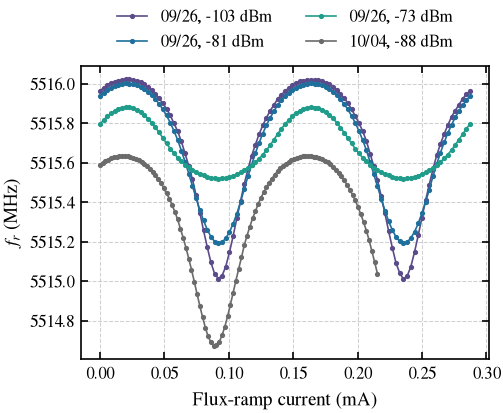

In [7]:
sw = sweeps["09/26"]
fig, ax = plt.subplots(figsize=(SINGLE, 2.8))
for P, color in zip((-40, -18, -10), ORDERED_3):
    k = sw.power_index(P)
    ax.plot(I["09/26"] * 1e3, par["09/26"]["fr"][k] / 1e6, ".-", color=color, lw=0.8,
            label=f"09/26, {sw.powers[k] + ATTEN:.0f} dBm")
ax.plot(I["10/04"] * 1e3, par["10/04"]["fr"][0] / 1e6, ".-", color=GRAY, lw=0.8,
        label=f"10/04, {sweeps['10/04'].powers[0] + ATTEN:.0f} dBm")
ax.set_xlabel("Flux-ramp current (mA)")
ax.set_ylabel("$f_r$ (MHz)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
grid(ax)
save(fig, "01_fr_vs_current", RESULTS / "figures")
plt.show()

## 4. The flux response at every power

The resonance follows the flux through the screened termination inductance, Eq. (2) of the paper in the low-power
limit, with the SQUID phase from Kepler's equation (Eq. 8):
$$f_r(I) = f_0 + \frac{4f_0^2}{Z_0}\,\frac{M_c^2}{L_s}\,\frac{\lambda\cos\phi}{1 + \lambda\cos\phi}, \qquad
\phi + \lambda\sin\phi = 2\pi\,\frac{M_\mathrm{fr}\,(I + I_0)}{\Phi_0}.$$
Five parameters are fitted: the bare frequency $f_0$ (where $\cos\phi = 0$ and the SQUID does not load the
resonator), $\lambda = L_s/L_J$, $M_c$, $M_\mathrm{fr}$ and the offset current $I_0$ from the trapped flux. Two are
fixed: $Z_0 = 50\,\Omega$, and $L_s$, because only $M_c^2/L_s$ enters and $L_s$ cannot be identified from these data;
we use 24.2 pH, the value the paper assumes (the FastHenry design value is 22.4 pH, see "What to try next").
`fit_flux_response` runs a differential-evolution search on the L1 norm of the residuals from 5 seeds, in a box
built from the data, and polishes the best solution with least squares; the $1\sigma$ errors come from that polish and
are statistical only. The 17 fits take about 30 s.

In [8]:
t0 = time.perf_counter()
flux_fits = {day: [fitting.fit_flux_response(I[day], fr_k, Ls=LS) for fr_k in par[day]["fr"]] for day in sweeps}
print(f"{sum(len(v) for v in flux_fits.values())} flux-response fits in {time.perf_counter() - t0:.0f} s\n")


def val_err(x, err, decimals):
    return f"{x:.{decimals}f}({err * 10 ** decimals:.0f})"


print(f"{'':7}{'P_chip':>7}{'f0 (MHz)':>16}{'lamb':>12}{'Mc (pH)':>18}{'Mfr (pH)':>14}{'rms (kHz)':>11}")
for day, sw in sweeps.items():
    for P, ff in zip(sw.powers + ATTEN, flux_fits[day]):
        e = ff.errors
        print(f"{day:7}{P:7.1f}{val_err(ff.f0 / 1e6, e[3] / 1e6, 4):>16}{val_err(ff.lamb, e[4], 4):>12}"
              f"{val_err(ff.Mc * 1e12, e[2] * 1e12, 3):>18}{val_err(ff.Mfr * 1e12, e[1] * 1e12, 3):>14}{ff.rms / 1e3:11.1f}")
print("value(1 sigma in the last digits)")

17 flux-response fits in 30 s

        P_chip        f0 (MHz)        lamb           Mc (pH)      Mfr (pH)  rms (kHz)
09/26   -102.9    5515.6889(2)   0.3386(5)          3.619(3)     14.408(2)        1.8
09/26   -100.9    5515.6889(2)   0.3379(5)          3.623(3)     14.407(2)        1.7
09/26    -98.9    5515.6890(2)   0.3375(4)          3.622(3)     14.409(2)        1.5
09/26    -96.9    5515.6887(1)   0.3362(4)          3.628(2)     14.406(2)        1.3
09/26    -94.9    5515.6888(1)   0.3343(4)          3.634(2)     14.408(2)        1.4
09/26    -92.9    5515.6890(1)   0.3308(4)          3.648(2)     14.409(2)        1.3
09/26    -90.9    5515.6889(1)   0.3259(4)          3.666(3)     14.409(2)        1.3
09/26    -88.9    5515.6885(2)   0.3183(5)          3.695(3)     14.409(2)        1.7
09/26    -86.9    5515.6885(2)   0.3068(6)          3.740(4)     14.410(3)        2.1
09/26    -84.9    5515.6886(3)  0.2887(10)          3.818(7)     14.410(4)        3.1
09/26    -82.9    5515.

The fitted $\lambda$ falls and $M_c$ rises steadily with power. The probe's RF flux averages the SQUID's response over
part of a flux quantum and flattens the modulation (the dressing that notebook 05 models); the formula above has no term
for it and can only follow by trading $\lambda$ against $M_c$, since the modulation depth goes roughly as
$M_c^2\lambda$. Above about $-83$ dBm at the chip the undressed model stops fitting: the residual grows, $\lambda$
collapses toward zero and $M_c$ runs away. The parameters are extracted at $-89$ dBm at the chip, below that limit and
at the readout power of the flux-ramp measurements of notebook 06. They already contain the dressing at that power,
which the simulation then applies once more (about 3 kHz at $-89$ dBm, half a percent of the linewidth; notebook 04
measures it).

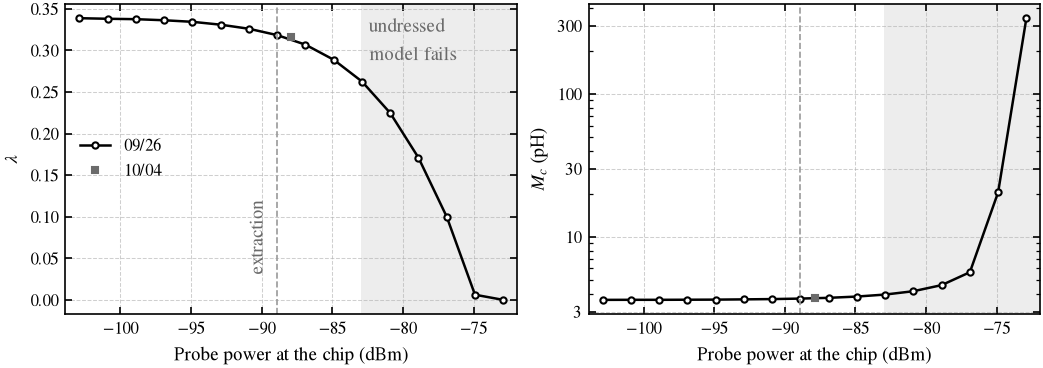

In [9]:
fig, (ax_l, ax_m) = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))
P26 = sweeps["09/26"].powers + ATTEN
P04 = sweeps["10/04"].powers + ATTEN
ax_l.plot(P26, [ff.lamb for ff in flux_fits["09/26"]], "o-", color=MEASURED, mfc="white", label="09/26")
ax_l.plot(P04, [ff.lamb for ff in flux_fits["10/04"]], "s", color=GRAY, label="10/04")
ax_m.semilogy(P26, [ff.Mc * 1e12 for ff in flux_fits["09/26"]], "o-", color=MEASURED, mfc="white")
ax_m.semilogy(P04, [ff.Mc * 1e12 for ff in flux_fits["10/04"]], "s", color=GRAY)
for ax in (ax_l, ax_m):
    ax.axvspan(-83, P26.max() + 1, color=GRAY, alpha=0.12, lw=0)
    ax.axvline(P_EXTRACT + ATTEN, color=ZERO, ls="--", lw=0.8)
    ax.set_xlim(P26.min() - 1, P26.max() + 1)
    ax.set_xlabel("Probe power at the chip (dBm)")
    grid(ax)
ax_l.text(P_EXTRACT + ATTEN - 0.7, 0.03, "extraction", rotation=90, color=GRAY, ha="right", va="bottom")
ax_l.text(-82.4, 0.345, "undressed\nmodel fails", color=GRAY, va="top")
ax_m.set_yticks([3, 10, 30, 100, 300], labels=["3", "10", "30", "100", "300"])
ax_l.set_ylabel(r"$\lambda$")
ax_m.set_ylabel(r"$M_c$ (pH)")
ax_l.legend(loc="center left")
save(fig, "01_squid_parameters_vs_power", RESULTS / "figures")
plt.show()

The $1\sigma$ errors above are statistical: they assume that the model is exact and the residuals uncorrelated. A
simple consistency check at the extraction power is to fit each flux quantum of the 09/26 sweep on its own (a few
seconds). One period constrains $M_\mathrm{fr}$ less, so the halves have larger errors; they agree with the joint fit
within about twice those errors, $M_\mathrm{fr}$ to 0.3% and $\lambda$ to 0.6%.

In [10]:
sw, k = sweeps["09/26"], k_ext["09/26"]
halves = {"both flux quanta": np.ones_like(sw.flux, bool), "first only": sw.flux <= 1, "second only": sw.flux >= 1}

print(f"09/26 at {sw.powers[k] + ATTEN:.1f} dBm at the chip")
print(f"{'':18}{'f0 (MHz)':>16}{'lamb':>12}{'Mc (pH)':>12}{'Mfr (pH)':>13}")
for name, sel in halves.items():
    ff = flux_fits["09/26"][k] if sel.all() else fitting.fit_flux_response(I["09/26"][sel], par["09/26"]["fr"][k, sel], Ls=LS)
    e = ff.errors
    print(f"{name:18}{val_err(ff.f0 / 1e6, e[3] / 1e6, 4):>16}{val_err(ff.lamb, e[4], 4):>12}"
          f"{val_err(ff.Mc * 1e12, e[2] * 1e12, 3):>12}{val_err(ff.Mfr * 1e12, e[1] * 1e12, 3):>13}")

09/26 at -88.9 dBm at the chip
                          f0 (MHz)        lamb     Mc (pH)     Mfr (pH)
both flux quanta      5515.6885(2)   0.3183(5)    3.695(3)    14.409(2)


first only            5515.6883(4)   0.3178(9)    3.698(6)   14.428(16)


second only           5515.6876(4)  0.3163(11)    3.709(7)   14.449(19)


## 5. Fig. 3: the flux response and its fit at three powers

The paper's Fig. 3 shows the measured $f_r$ (open markers, every second point) and the fitted flux response at three
VNA powers, $-40$, $-26$ and $-12$ dBm, labelled with the power at the chip, and the residuals below. At the two lower
powers the residuals are a few kHz, small against the 580 kHz linewidth; at the highest power the undressed model no
longer has the shape of the data.

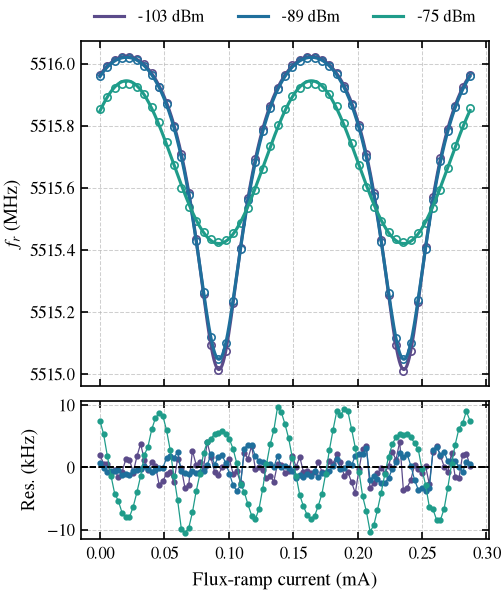

In [11]:
sw = sweeps["09/26"]
fig, axes = plt.subplots(2, 1, figsize=(SINGLE, 4.0), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]})
for P, color in zip((-40, -26, -12), ORDERED_3):
    k = sw.power_index(P)
    plots.flux_response(flux_fits["09/26"][k], axes=axes, every=2, color=color, label=f"{sw.powers[k] + ATTEN:.0f} dBm")
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
axes[1].set_xlabel("Flux-ramp current (mA)")
for ax in axes:
    grid(ax)
save(fig, "01_flux_response", RESULTS / "figures")
plt.show()

## 6. Table I

The parameters of each day are the medians of the circle-fit parameters over the 101 flux points at the extraction
power and the flux-response fit at that power (`fitting.summarize_channel`). Two are derived: $L_J = L_s/\lambda$, and
the trapped flux $\phi_\mathrm{tr} = 2\pi I_\mathrm{tr} M_\mathrm{fr}/\Phi_0$, where $I_\mathrm{tr}$ is the offset
current measured from the point $\phi = \pi/2$ (SQUID unloaded, $f_r = f_0$) and wrapped into $\pm\Phi_0/2$; the
configuration files store it as `trapped_current`. The design values $L_c = 49.1$ pH, $C_c = 9.4$ fF, $Z_0 = 50\,\Omega$
and the detector-input mutual $M_\mathrm{in} = 246$ pH are fixed. The numbers are recorded in `results/values.json`
(`Qr0926`, `QcDcm0926`, `Qi0926`, `alpha0926`, `f0_0926`, `lamb0926`, `Mc0926`, `Mfr0926`, `phitr0926` and the same with
`1004`).

In [12]:
days = list(sweeps)
table = {day: fitting.summarize_channel(par[day]["Qr"][k_ext[day]], par[day]["Qc_abs"][k_ext[day]],
                                        par[day]["alpha"][k_ext[day]], flux_fits[day][k_ext[day]]) for day in days}
P_chip = {day: sweeps[day].powers[k_ext[day]] + ATTEN for day in days}


def table_row(label, cells):
    print(f"{label:<32}" + "".join(f"{c:>15}" for c in cells))


table_row("", days)
table_row("probe power at the chip (dBm)", [f"{P_chip[d]:.1f}" for d in days])
print("resonator: medians of the circle fits")
table_row("  Qr", [f"{table[d]['Qr']:.1f}" for d in days])
table_row("  |Qc_hat|", [f"{table[d]['Qc_abs']:.1f}" for d in days])
table_row("  alpha (rad)", [f"{table[d]['alpha']:.4f}" for d in days])
table_row("  Qc = |Qc_hat|/cos(alpha)", [f"{table[d]['Qc']:.0f}" for d in days])
table_row("  Qi", [f"{table[d]['Qi']:.0f}" for d in days])
print(f"rf-SQUID: flux-response fit, Ls = {LS * 1e12:.1f} pH fixed")
table_row("  f0 (MHz)", [val_err(table[d]["f0"] / 1e6, table[d]["err"][3] / 1e6, 4) for d in days])
table_row("  lamb", [val_err(table[d]["lamb"], table[d]["err"][4], 4) for d in days])
table_row("  LJ = Ls/lamb (pH)", [f"{LS / table[d]['lamb'] * 1e12:.1f}" for d in days])
table_row("  Mc (pH)", [val_err(table[d]["Mc"] * 1e12, table[d]["err"][2] * 1e12, 3) for d in days])
table_row("  Mfr (pH)", [val_err(table[d]["Mfr"] * 1e12, table[d]["err"][1] * 1e12, 3) for d in days])
table_row("  phi_tr (rad)", [f"{table[d]['phi_tr']:.3f}" for d in days])
table_row("  trapped current (uA)", [f"{table[d]['trapped_current'] * 1e6:.2f}" for d in days])
table_row("  rms residual (kHz)", [f"{flux_fits[d][k_ext[d]].rms / 1e3:.1f}" for d in days])
print(f"\n10/04 minus 09/26: f0 {(table['10/04']['f0'] - table['09/26']['f0']) / 1e3:+.0f} kHz, "
      f"phi_tr {table['10/04']['phi_tr'] - table['09/26']['phi_tr']:+.3f} rad")

for day, tag in (("09/26", "0926"), ("10/04", "1004")):
    t, note = table[day], f"Table I, {day}, at {P_chip[day]:.1f} dBm at the chip (01)"
    store.record(f"Qr{tag}", t["Qr"], "{:.1f}", f"loaded Q, median of the circle fits; {note}")
    store.record(f"QcDcm{tag}", t["Qc"], "{:.0f}", f"Qc = |Qc_hat|/cos(alpha); {note}")
    store.record(f"Qi{tag}", t["Qi"], "{:.0f}", f"internal Q; {note}")
    store.record(f"alpha{tag}", t["alpha"], "{:.4f}", f"asymmetry angle, rad; {note}")
    store.record(f"f0_{tag}", t["f0"] / 1e6, "{:.3f}", f"bare resonance f0, MHz; {note}")
    store.record(f"lamb{tag}", t["lamb"], "{:.4f}", f"hysteresis parameter Ls/LJ; {note}")
    store.record(f"Mc{tag}", t["Mc"] * 1e12, "{:.3f}", f"SQUID-resonator mutual, pH; {note}")
    store.record(f"Mfr{tag}", t["Mfr"] * 1e12, "{:.3f}", f"flux-ramp mutual, pH; {note}")
    store.record(f"phitr{tag}", t["phi_tr"], "{:.3f}", f"trapped flux phase from phi = pi/2, rad; {note}")
store.record("PextractVNA", sweeps["09/26"].powers[k_ext["09/26"]], "{:.0f}", "extraction power at the VNA, dBm (01)")
store.record("PextractChip", P_chip["09/26"], "{:.0f}", "extraction power at the chip, 09/26, dBm (01)")
store.record("PextractChipOct", P_chip["10/04"], "{:.0f}", "extraction power at the chip, 10/04, dBm (01)")
store.record("fzero", table["09/26"]["f0"] / 1e6, "{:.3f}", "f0 of the 09/26 configuration, MHz (01)")
store.record("LsVal", LS * 1e12, "{:.1f}", "SQUID loop inductance assumed in the flux fits, pH (01)")
print("\nrecorded in results/values.json:")
for tag in ("0926", "1004"):
    print("  " + ", ".join(f"{n}{tag} {store.text(n + tag)}" for n in ("Qr", "QcDcm", "alpha", "f0_", "lamb", "Mc", "Mfr", "phitr")))

                                          09/26          10/04
probe power at the chip (dBm)             -88.9          -87.9
resonator: medians of the circle fits
  Qr                                     9514.9         9526.8
  |Qc_hat|                              10435.9        10422.3
  alpha (rad)                           -0.0864        -0.0890
  Qc = |Qc_hat|/cos(alpha)                10475          10464
  Qi                                     103803         106398
rf-SQUID: flux-response fit, Ls = 24.2 pH fixed
  f0 (MHz)                         5515.6885(2)   5515.3051(2)
  lamb                                0.3183(5)      0.3156(7)
  LJ = Ls/lamb (pH)                        76.0           76.7
  Mc (pH)                              3.695(3)       3.702(4)
  Mfr (pH)                            14.409(2)      14.401(4)
  phi_tr (rad)                           -2.791         -2.651
  trapped current (uA)                   -63.75         -60.59
  rms residual (kHz)            

## 7. The configuration files

`uc.write_config` writes one TOML file per day into `results/configs/`: $f_0$, $\lambda$, $M_c$, $M_\mathrm{fr}$ and the
trapped current from the flux fit; $Q_r$, $|\hat Q_c|$ and $\alpha$ from the circle fits (the loader converts
$|\hat Q_c|$ to $Q_c$); the fixed values; and in `[simulation]` the extraction power at the chip and a default flux-ramp
rate (1 kHz for 09/26, 10 kHz for 10/04, as in the shipped files). The 09/26 file is printed in full, then every numeric
field of both files is compared with the copies shipped in `configs/`, which were made by the same pipeline. The fitted
fields agree to better than $10^{-9}$. `P_rf_dBm` is not fitted here: it is the extraction power plus the attenuation of
notebook 05, so it differs slightly if that attenuation differs from the one the shipped files were written with.

In [13]:
names = {"09/26": "nist_res2_2026-09-26.toml", "10/04": "nist_res2_2026-10-04.toml"}
freq_fr = {"09/26": 1000.0, "10/04": 10000.0}
(RESULTS / "configs").mkdir(parents=True, exist_ok=True)

written, text = {}, {}
for day in days:
    t = table[day]
    written[day] = RESULTS / "configs" / names[day]
    text[day] = uc.write_config(written[day], t["f0"], t["Qr"], t["Qc_abs"], t["alpha"], t["lamb"], t["Mc"], t["Mfr"],
                                t["trapped_current"], Ls=LS, P_rf_dBm=P_chip[day], freq_fr=freq_fr[day])
print(written["09/26"])
print(text["09/26"])

new = {day: uc.Config(written[day]).raw for day in days}
ref = {day: uc.Config(CONFIGS / names[day]).raw for day in days}
print(f"{'field':<28}" + "".join(f"{day + ' written':>22}{'rel. diff':>11}" for day in days))
worst = 0.0
for section, entries in new["09/26"].items():
    for key in entries:
        cells = ""
        for day in days:
            a, b = new[day][section][key], ref[day][section][key]
            rel = abs(a - b) / abs(b)
            worst = worst if key == "P_rf_dBm" else max(worst, rel)
            cells += f"{a:22.12g}{rel:11.1e}"
        print(f"{section + '.' + key:<28}" + cells)

A_shipped = ref["09/26"]["simulation"]["P_rf_dBm"] - sweeps["09/26"].powers[k_ext["09/26"]]
print(f"\nlargest relative difference of the fitted fields: {worst:.1e}")
print(f"P_rf_dBm: attenuation {ATTEN:.7f} dB here, {A_shipped:.7f} dB in the shipped files")

results/configs/nist_res2_2026-09-26.toml
[globals]
Phi0 = 2.068e-15

[simulation]
nPhi0 = 1
freq_fr = 1000.0
P_rf_dBm = -88.9

[resonators]
num_channels = 1
f0 = 5515688502.859899
Qr = 9514.855863368264
Qc = 10435.936914042693
Qi = 103803.44427906249
alpha = -0.08641016322915647
Cc = 9.4e-15
Lc = 4.91e-11

[squids]
Ls = 2.42e-11
Lj = 7.603085405980249e-11
lamb = 0.31829183427250934
Mc = 3.6949161560919655e-12
Mfr = 1.4409050834688806e-11
Min = 2.46e-10
Mtr = 1.4409050834688806e-11
trapped_current = -6.375310935107854e-05

field                                09/26 written  rel. diff         10/04 written  rel. diff
globals.Phi0                             2.068e-15    0.0e+00             2.068e-15    0.0e+00
simulation.nPhi0                                 1    0.0e+00                     1    0.0e+00
simulation.freq_fr                            1000    0.0e+00                 10000    0.0e+00
simulation.P_rf_dBm                          -88.9    2.1e-05                 -87.9    2.2e

Round trip: the written configuration is loaded as a device, its flux-ramp line is set to every bias current of the
sweep, and the zero-power resonance `Channel.get_fr(0.0)` is compared with the measured $f_r$. The simulation does not
evaluate the fitted formula: it takes the screening from the Wegner series (Eq. 10), which carries the RF dressing, puts
it into the lumped resonance (Eq. 7), and pins that resonance to $f_0$ through the same series at
$\phi_\mathrm{ext} = \pi/2 + \lambda$. The deviation is therefore the fit residual plus whatever separates the series at
zero power from the exact screening (Kepler's equation) that the fit uses. The last lines of each day measure that
difference with `uc.screening_exact` and convert it, relative to the calibration point, into frequency with the
prefactor of Eq. (2).

In [14]:
from scipy.special import jv


def rms(x):
    return np.sqrt(np.mean(np.square(x)))


for day in days:
    ch = uc.load_config(written[day])[0]
    ch.line("FluxRamp").I = I[day]
    fr_meas, ff = par[day]["fr"][k_ext[day]], flux_fits[day][k_ext[day]]
    fr_config = ch.get_fr(0.0)
    dev = fr_config - fr_meas
    model_diff = fr_config - ff.model(I[day])

    sq = ch.squid
    w, c = uc.screening_weights(sq.lamb)
    S_exact = uc.screening_exact(sq.phi_ext, 0.0, sq.lamb)
    dS = sq.get_screening_factor(0.0) - S_exact
    dS_cal = uc.screening_factor(np.pi / 2 + sq.lamb, 0.0, (w, c))    # the exact value is 0
    from_series = 4 * ch.f0 ** 2 / ch.Z0 * ch.Mc ** 2 / sq.Ls * (dS - dS_cal)
    w_kepler = 2 / c * (-1) ** (c + 1) * jv(c, c * sq.lamb)
    dS_kepler = uc.screening_factor(sq.phi_ext, 0.0, (w_kepler, c)) - S_exact

    print(f"{day}: config - measured fr      rms {rms(dev) / 1e3:.2f} kHz, mean {dev.mean() / 1e3:+.2f} kHz, "
          f"max {np.abs(dev).max() / 1e3:.2f} kHz")
    print(f"       fit residual              rms {ff.rms / 1e3:.2f} kHz")
    print(f"       config - fitted model     {model_diff.min() / 1e3:+.2f} to {model_diff.max() / 1e3:+.2f} kHz, "
          f"mean {model_diff.mean() / 1e3:+.2f} kHz")
    print(f"       series - exact screening  {dS.min():+.1e} to {dS.max():+.1e} over the sweep, "
          f"{dS_cal:+.1e} at the calibration point")
    print(f"       ... in frequency          mean {from_series.mean() / 1e3:+.2f} kHz; leaves "
          f"{rms(model_diff - from_series) / 1e3:.2f} kHz rms of the model difference")
    print(f"       Kepler weights - exact    {np.abs(dS_kepler).max():.0e} at most\n")

09/26: config - measured fr      rms 2.86 kHz, mean -2.44 kHz, max 6.18 kHz
       fit residual              rms 1.66 kHz
       config - fitted model     -5.06 to +0.00 kHz, mean -2.44 kHz
       series - exact screening  -1.9e-03 to +1.8e-03 over the sweep, +1.8e-03 at the calibration point
       ... in frequency          mean -2.46 kHz; leaves 0.04 kHz rms of the model difference
       Kepler weights - exact    1e-05 at most

10/04: config - measured fr      rms 2.89 kHz, mean -2.27 kHz, max 5.93 kHz
       fit residual              rms 2.08 kHz
       config - fitted model     -4.86 to +0.00 kHz, mean -2.27 kHz
       series - exact screening  -1.8e-03 to +1.7e-03 over the sweep, +1.7e-03 at the calibration point
       ... in frequency          mean -2.29 kHz; leaves 0.04 kHz rms of the model difference
       Kepler weights - exact    1e-05 at most



The configuration reproduces the measured $f_r$ to 2.9 kHz rms on both days, against fit residuals of 1.7 and 2.1 kHz.
The excess is an offset of 0 to $-5$ kHz that depends on the flux (under 1% of the 580 kHz linewidth), and the series
accounts for all of it but 0.04 kHz rms, the second-order term of the lumped resonance. It is not a truncation error:
the coefficients in `uc.squid.WEGNER_A` are Table 1 of Wegner et al. (2022), a 10th-order expansion in $\lambda$ of the
solution of a quadratic approximation to the SQUID equation (their Eq. 19), and they agree with the exact expansion only
up to $\lambda^3$. At zero power the exact screening is the Fourier series of Kepler's equation,
$S = \sum_c 2(-1)^{c+1}J_c(c\lambda)\cos(c\phi_\mathrm{ext})$; with these coefficients the same eleven harmonics match
`uc.screening_exact` to $10^{-5}$ (last line), against $2\times10^{-3}$ (0.3% of the swing of $S$) for the published
ones. The simulations here and in the paper use the published coefficients, so their flux response carries the same
offset.

## What to try next

* **Extract at another power.** Set `P_EXTRACT = -40` ($-103$ dBm at the chip) and rerun: $\lambda$ rises to 0.339
  and $M_c$ falls. To see how much of the measured power dependence the double dressing at $-89$ dBm accounts for, set
  `CONFIG = RESULTS / "configs" / "nist_res2_2026-09-26.toml"` in notebook 05 (by default it loads the shipped copy in
  `configs/`, which this notebook never overwrites) and rerun it.
* **Change $L_s$.** $L_s$ cannot be identified from the flux response, but the RF flux that dresses the SQUID,
  $M_c I_T$, depends on $M_c$ alone. Refit with `LS = uc.fitting.LS_DESIGN` (22.4 pH, the FastHenry design value):
  $M_c$ scales as $\sqrt{L_s}$ and the zero-power curve stays the same. Rerun notebook 05 on the new file, as above, to
  see what that does to the power dependence and the fitted attenuation. Both experiments overwrite `results/configs/`
  and entries of `results/values.json` (`Mc0926`, `LsVal`, `Atten`, ...); rerun 01 and 05 as shipped to restore them,
  or `tests/test_example_results.py` fails.
* **Your own channel.** Any `.npz` with `frequencies`, `flux_bias`, `vna_powers` and `s21_data` of shape
  (power, flux, frequency) runs through steps 2-6 with the paths, the day labels, `M_NOMINAL` and `P_EXTRACT` changed;
  in step 7 drop the comparison with `configs/`. The flux-response fit expects the sweep to span one to two flux
  quanta. For a whole chip in one wide sweep see notebook 02 (`fitting.fit_all_resonances`).